In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

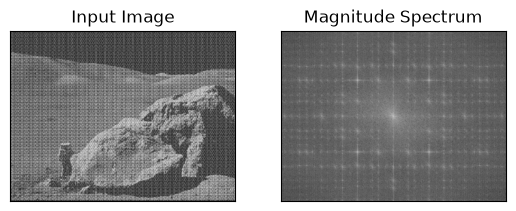

In [2]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [11]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
U, V = np.meshgrid(np.arange(cols) - ccol, np.arange(rows) - crow)
D2 = U**2 + V**2

D0 = 30
mask_hp = 1 - np.exp(-D2 / (2 * D0**2))
mask = np.dstack([mask_hp, mask_hp]).astype(np.float32)

fshift = dft_shift * mask
f_ishift = np.fft.ifftshift(fshift, axes=(0, 1))
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

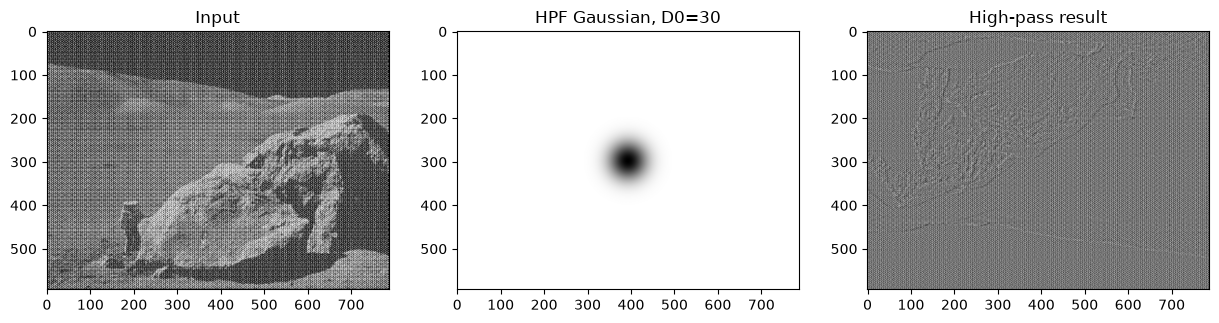

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Input')

ax[1].imshow(mask_hp, cmap='gray')
ax[1].set_title(f'HPF Gaussian, D0={D0}')

ax[2].imshow(img_back, cmap='gray')
ax[2].set_title('High-pass result')

plt.show()

# Реализуйте вычисление свертки с помощью преобразования Фурье

# Реализуйте удаление периодического шума с помощью преобразования Фурье